# Udeco2 / Udeco3 固定区间统计

目标：对每个样本、每个通道统计前 30 s，以及运动开始后 15–35 s 内阈值上侧/下侧信号的均值和样本方差。单文件验证图与批处理调用完全相同的统计函数。

统计值使用轻度中值滤波信号；灰色原始曲线仅用于人工对照。本 Notebook 不执行 H/M/L 状态分类。

In [4]:
# Cell 1 - Import
from __future__ import annotations

import platform
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from udeco_analysis import load_udeco_sample
from udeco_interval_analysis import (
    IntervalAnalysisConfig,
    analyze_interval_batch,
    analyze_interval_sample,
    export_interval_excel,
    export_interval_means_excel,
    plot_interval_validation,
)

print(f'Python: {platform.python_version()} | 工作目录: {Path.cwd()}')

Python: 3.10.20 | 工作目录: d:\MHLcode


## 用户参数区

先运行单文件验证并检查三个统计区域；确认结果后再将 `RUN_BATCH` 改为 `True`。

In [ ]:
# Cell 2 - User configuration
DATA_ROOT = Path(r'D:/MHLcode/subject_data')
SUBJECTS = ['ts', 'lyx', 'lzj', 'cgx', 'pjy', 'hjy']
FS_HZ = 100  # 复用原始协议采样率

# 中值滤波窗口。调大：更抗尖峰但可能压平快速变化；调小：保真但更受噪声影响。建议 0.01–0.03 s。
MEDIAN_FILTER_SEC = 0.03
# ACC 无法识别运动起点时使用的回退值；回退样本会在 Excel 中明确标记。
FALLBACK_MOTION_START_SEC = 70.0

# 单文件验证：必须指向 *_sensor.csv，而不是 *_HRdata.csv。
VALIDATION_FILE = DATA_ROOT / 'ts' / 'ts_gripper_1_sensor.csv'

# 人工确认验证图之前保持 False；改为 True 后才处理全部受试者。
RUN_BATCH = True
OUTPUT_EXCEL = Path('outputs/udeco_interval_statistics.xlsx')

In [14]:
# Cell 3 - 统一配置；时间区间均为左闭右开
CONFIG = IntervalAnalysisConfig(
    median_filter_sec=MEDIAN_FILTER_SEC,
    pre_duration_sec=30.0,
    motion_offset_start_sec=15.0,
    motion_offset_end_sec=35.0,
    fallback_motion_start_sec=FALLBACK_MOTION_START_SEC,
)
display(pd.Series(asdict(CONFIG), name='value').to_frame())

,value
median_filter_sec,3.000000e-02
pre_duration_sec,3.000000e+01
motion_offset_start_sec,1.500000e+01
motion_offset_end_sec,3.500000e+01
fallback_motion_start_sec,7.000000e+01
epsilon,1.000000e-09
motion_calibration_sec,3.000000e+01
motion_window_sec,8.000000e+00
motion_step_sec,1.000000e+00
motion_threshold_sigma,3.000000e+00


## 单文件读取检查

先确认文件、共享 `ck.mat`、时间轴和 Udeco2/3 能正常读取。

In [15]:
# Cell 4 - 单文件输入检查
validation_loaded = None
if not VALIDATION_FILE.is_file():
    print(f'VALIDATION_FILE 不存在，跳过验证：{VALIDATION_FILE}')
else:
    validation_loaded = load_udeco_sample(VALIDATION_FILE, data_root=DATA_ROOT, fs=FS_HZ)
    display(pd.Series({
        'sample_name': validation_loaded.sample_name,
        'n_samples': len(validation_loaded.time_s),
        'duration_s': len(validation_loaded.time_s) / validation_loaded.fs,
        'fs_hz': validation_loaded.fs,
        'sequence_interpolated': int(validation_loaded.qc['InterpFlag'].sum()),
        'near_zero_denominator': int(validation_loaded.qc['ud_denominator_near_zero'].sum()),
    }, name='value').to_frame())

,value
sample_name,ts_gripper_1
n_samples,20270
duration_s,202.7
fs_hz,100
sequence_interpolated,0
near_zero_denominator,0


## Validation / Manual Inspection

图中绿色背景为区域 A（前 30 s），黄色背景为运动后 15–35 s；红点为区域 B（分界线 1 以上），蓝点为区域 C（分界线 2 以下）。

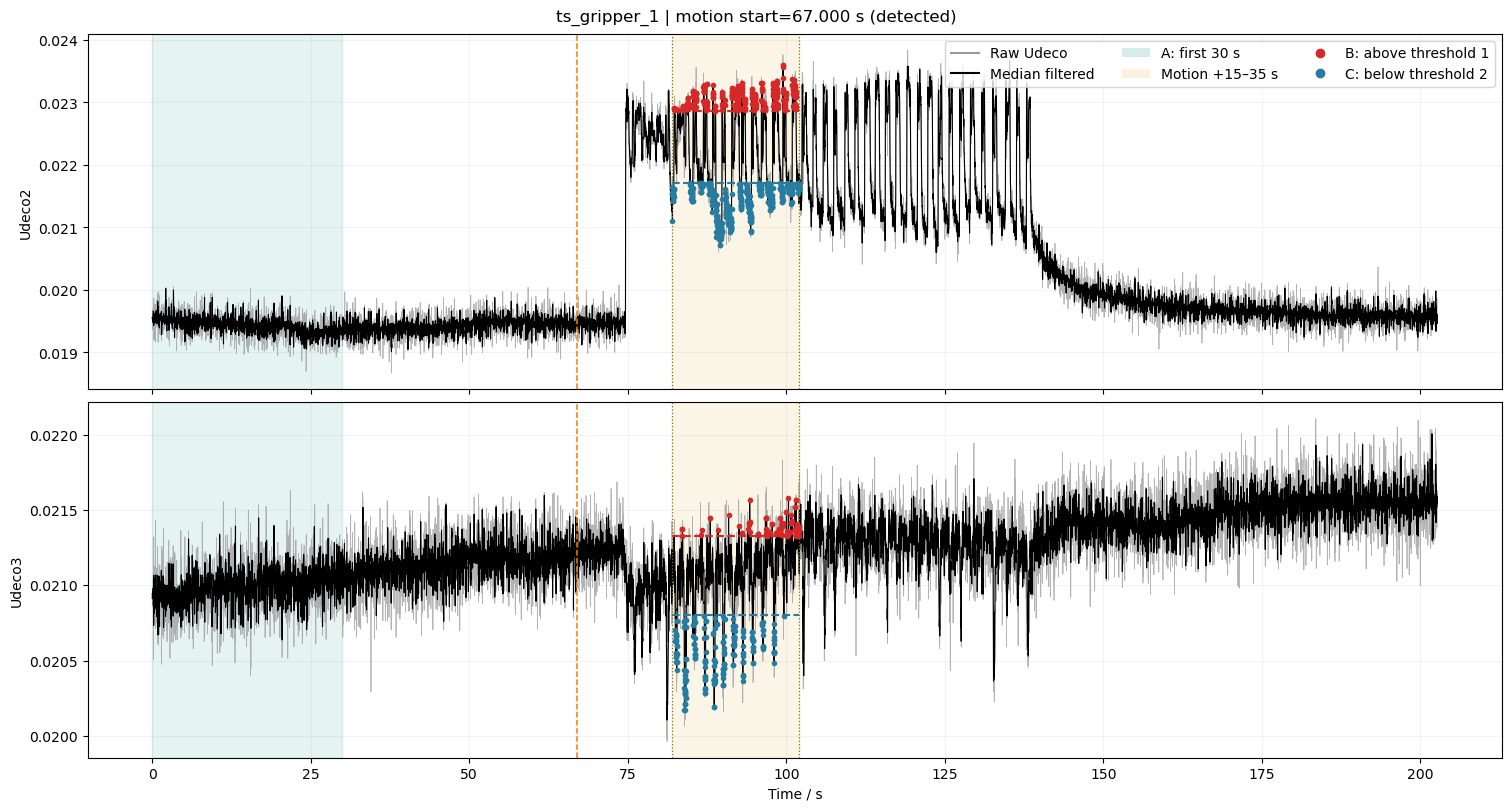

In [16]:
# Cell 5 - 单文件双通道统计与可视化
validation_result = None
validation_figure = None
if validation_loaded is None:
    print('无可用单文件，Validation 安全跳过。')
else:
    validation_result = analyze_interval_sample(
        VALIDATION_FILE, data_root=DATA_ROOT, fs=FS_HZ, config=CONFIG
    )
    validation_figure = plot_interval_validation(validation_result)
    plt.show()

### 单文件统计数值

每个通道展示 6 个核心统计值、两个阈值、入选点数及 QC。方差为样本方差（`ddof=1`）。

In [9]:
# Cell 6 - 单文件结果表
if validation_result is None:
    print('无 validation_result。')
else:
    records = []
    for channel in ('Udeco2', 'Udeco3'):
        channel_result = validation_result['channels'][channel]
        records.append({
            'channel': channel,
            **channel_result['statistics'],
            'channel_QC': ';'.join(channel_result['qc_flags']) or 'OK',
        })
    print(
        f"运动起点: {validation_result['motion_start_s']:.3f} s "
        f"({validation_result['motion_start_source']}) | QC: {validation_result['QC_flag']}"
    )
    display(pd.DataFrame(records))

运动起点: 67.000 s (detected) | QC: OK


,channel,pre30_mean,pre30_var,interval_mean,interval_max,interval_min,threshold1,threshold2,upper_mean,upper_var,lower_mean,lower_var,upper_n,lower_n,channel_QC
0,Udeco2,0.019438,1.342428e-08,0.022146,0.023594,0.020724,0.022870,0.021719,0.023059,1.885728e-08,0.021405,6.006934e-08,394,669,OK
1,Udeco3,0.020994,8.997975e-09,0.021076,0.021577,0.020174,0.021326,0.020805,0.021381,3.161842e-09,0.020548,2.320715e-08,114,245,OK


## 全受试者批处理

只有 `RUN_BATCH=True` 时执行。单样本失败保留 NaN 行，不阻断其他样本。

In [10]:
# Cell 7 - 批处理
batch_results = {}
if not RUN_BATCH:
    print('RUN_BATCH=False：跳过全部受试者批处理。')
else:
    batch_results = analyze_interval_batch(DATA_ROOT, SUBJECTS, fs=FS_HZ, config=CONFIG)
    overview = pd.DataFrame([
        {
            'subject': subject,
            'sample_rows': len(result['sample_results']),
            'ok_rows': int((result['sample_results']['analysis_status'] == 'ok').sum()),
            'qc_rows': len(result['qc']),
        }
        for subject, result in batch_results.items()
    ])
    display(overview)

RUN_BATCH=False：跳过全部受试者批处理。


## Excel 输出

每个受试者一个 sheet；Part A 为每样本一行的 12 个核心统计值及诊断列，Part B 为跳过文件和 QC。

In [11]:
# Cell 8 - 写出 Excel
excel_path = None
if batch_results:
    excel_path = export_interval_excel(batch_results, OUTPUT_EXCEL)
    print(f'Excel 已输出：{excel_path.resolve()}')
else:
    print('无批处理结果，跳过 Excel。')

无批处理结果，跳过 Excel。


In [ ]:
# Cell 9 - 精简 Excel：中文运动类型 + Udeco2/3 各三个区域均值（共 6 个数值列）
MEANS_ONLY_EXCEL = Path('outputs/udeco_interval_means_only.xlsx')
means_excel_path = None
if batch_results:
    means_excel_path = export_interval_means_excel(batch_results, MEANS_ONLY_EXCEL)
    print(f'精简 Excel 已输出：{means_excel_path.resolve()}')
else:
    print('无批处理结果，跳过精简 Excel。请先设置 RUN_BATCH=True 并运行批处理单元格。')

## QC 汇总检查

重点检查 `fallback_70s`、区间超出记录范围、无阈值入选点和读取失败。

In [12]:
# Cell 10 - 批次 QC
if not batch_results:
    print('无批处理结果可检查。')
else:
    for subject, result in batch_results.items():
        print(f'=== {subject} ===')
        display(result['sample_results'].head())
        if not result['qc'].empty:
            display(result['qc'].head(20))

无批处理结果可检查。


## 下一步

1. 先核对验证图中的前 30 s、运动起点和运动后 15–35 s。
2. 检查红点/蓝点是否符合两个分界线定义。
3. 如需调整滤波，仅修改 `MEDIAN_FILTER_SEC` 并重新构建 `CONFIG`。
4. 确认后设置 `RUN_BATCH=True`，重新运行批处理、Excel 和 QC 单元格。